<a href="https://colab.research.google.com/github/gokulravi123/IMDB/blob/main/IMDB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:




VOCAB_SIZE = 10000
MAX_LENGTH = 200

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=VOCAB_SIZE
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))
print("First review:", X_train[0][:20])
print("First review label:", y_train[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training reviews: 25000
Testing reviews: 25000
First review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
First review label: 1


In [3]:
X_train = pad_sequences(
    X_train,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    X_test,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (25000, 200)
Testing shape: (25000, 200)


In [4]:

model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=64,
        mask_zero=True
    ),

    Bidirectional(
        LSTM(64, return_sequences=False)
    ),

    Dropout(0.5),

    Dense(32, activation="relu"),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [5]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 141s 436ms/step - accuracy: 0.7157 - loss: 0.5510 - val_accuracy: 0.8380 - val_loss: 0.3714
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 125s 383ms/step - accuracy: 0.8804 - loss: 0.2974 - val_accuracy: 0.8714 - val_loss: 0.3151
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 120s 383ms/step - accuracy: 0.9198 - loss: 0.2135 - val_accuracy: 0.8630 - val_loss: 0.3321
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 141s 378ms/step - accuracy: 0.9437 - loss: 0.1577 - val_accuracy: 0.8638 - val_loss: 0.3504


In [6]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

782/782 ━━━━━━━━━━━━━━━━━━━━ 44s 57ms/step - accuracy: 0.8502 - loss: 0.3575
Test Loss: 0.3575
Test Accuracy: 85.02%


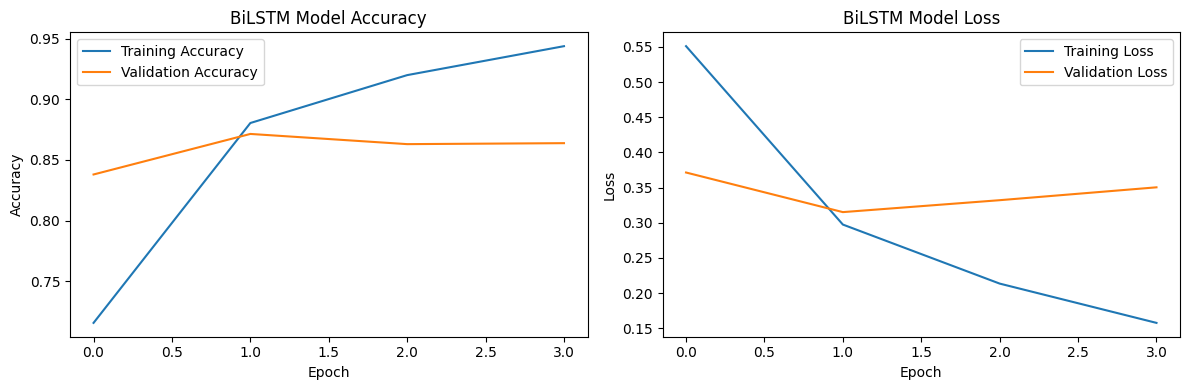

In [7]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("BiLSTM Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("BiLSTM Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [8]:
y_prob = model.predict(X_test, verbose=0)
y_pred = (y_prob >= 0.5).astype(int).ravel()

print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

    Negative       0.84      0.87      0.85     12500
    Positive       0.86      0.83      0.85     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000

Confusion Matrix:
[[10847  1653]
 [ 2093 10407]]


In [9]:
import re

word_index = imdb.get_word_index()

def preprocess_review(review):
    words = re.findall(r"\b\w+\b", review.lower())

    sequence = [1]  # IMDB start token

    for word in words:
        index = word_index.get(word)

        if index is None:
            sequence.append(2)  # Unknown word
        else:
            index = index + 3

            if index < VOCAB_SIZE:
                sequence.append(index)
            else:
                sequence.append(2)

    padded_review = pad_sequences(
        [sequence],
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post"
    )

    return padded_review

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [10]:
new_reviews = [
    "The movie was excellent and the acting was wonderful",
    "The movie was boring and the story was terrible"
]

for review in new_reviews:
    processed_review = preprocess_review(review)

    probability = model.predict(
        processed_review,
        verbose=0
    )[0][0]

    sentiment = "Positive" if probability >= 0.5 else "Negative"

    print("\nReview:", review)
    print("Sentiment:", sentiment)
    print(f"Positive probability: {probability:.4f}")


Review: The movie was excellent and the acting was wonderful
Sentiment: Positive
Positive probability: 0.9411

Review: The movie was boring and the story was terrible
Sentiment: Negative
Positive probability: 0.0251


In [11]:
model.save("imdb_bilstm_model.keras")

print("BiLSTM model saved successfully!")

BiLSTM model saved successfully!


In [12]:
loaded_model = tf.keras.models.load_model(
    "imdb_bilstm_model.keras"
)